# 01 — Hiểu dataset CIC-DDoS2019

Notebook này dành cho người **chưa biết gì về dataset**. Đọc từ trên xuống, mỗi phần trả lời một câu hỏi:

1. CIC-DDoS2019 là gì, ai làm, đo cái gì?
2. Một dòng dữ liệu ("flow") nghĩa là gì?
3. Có những loại tấn công nào, chúng hoạt động ra sao?
4. Dữ liệu trong project trông thế nào (số lượng, mất cân bằng)?
5. Các cột (đặc trưng) nghĩa là gì, cột nào quan trọng?
6. Đặc trưng phân biệt tấn công với bình thường như thế nào?
7. Chất lượng dữ liệu: inf, NaN, trùng lặp, cột hằng.
8. **Hai ngày khác nhau ra sao** — điểm mấu chốt giải thích kết quả thí nghiệm.
9. Dữ liệu được chia cho các client FL thế nào (Non-IID S1–S4)?
10. Chuẩn hóa liên kết có thật sự giống chuẩn hóa tập trung không?

> Chạy lần lượt từng ô (Shift+Enter). Kernel: **Python (fl-ddos)**.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

from fl_ddos.features import normalize_label, slog1p, load_meta
from prepare.preprocess_csv import snake
from analysis.plots import SERIES, INK, INK2, GRID   # cùng bảng màu & style với hình báo cáo
%matplotlib inline

pd.set_option("display.max_columns", 50, "display.width", 160)
RAW = ROOT / "data" / "raw" / "cicddos2019"
DATA = ROOT / "data"
print("Thư mục dự án:", ROOT)

Thư mục dự án: D:\Work\Learn\HK7_2026-2027\ATTT\Final_Exam


## 1. CIC-DDoS2019 là gì?

- Do **Canadian Institute for Cybersecurity (CIC), Đại học New Brunswick** công bố năm 2019 (Sharafaldin và cộng sự, ICCST 2019).
- Nhóm tác giả dựng một mạng thử nghiệm (testbed): một mạng **nạn nhân** (máy chủ web, máy trạm Windows/Ubuntu…) và một mạng **tấn công** bên ngoài. Họ cho người dùng giả lập sinh traffic bình thường (web, email, FTP, SSH…), rồi lần lượt phát động từng loại DDoS.
- Toàn bộ gói tin được ghi lại thành **PCAP**, sau đó đưa qua công cụ **CICFlowMeter** để gom gói tin thành **flow** và tính hơn 80 đặc trưng thống kê cho mỗi flow → ra file CSV.
- Ghi trong **2 ngày**:
  - **Ngày 12/01/2019** — tác giả gọi là ngày *training*: 12 loại tấn công.
  - **Ngày 11/03/2019** — ngày *testing*: 7 loại tấn công, trong đó **PortScan (Portmap) chỉ có ở ngày này**.

Đồ án dùng đúng cách chia đó: **train trên ngày 12/01, test trên ngày 11/03**. Không chia ngẫu nhiên trong cùng một ngày, vì các flow cùng một đợt tấn công giống hệt nhau → kết quả đẹp giả (~99,9%).

### Flow là gì?
Một **flow** = tập các gói tin có cùng **5-tuple** (IP nguồn, IP đích, port nguồn, port đích, giao thức) trong một khoảng thời gian, tính cả hai chiều:
- **Forward (Fwd)** = chiều từ bên khởi tạo kết nối → bên kia.
- **Backward (Bwd)** = chiều ngược lại (phản hồi).

Mỗi **dòng** trong dataset là **một flow**, và mỗi flow có nhãn `BENIGN` (bình thường) hoặc tên một loại tấn công. Mô hình của đồ án học phân loại **flow** → 0 (bình thường) / 1 (DDoS).

## 2. Các loại tấn công DDoS trong dataset

CIC chia tấn công thành 2 họ lớn:

**(a) Reflection / Amplification (phản xạ – khuếch đại)** — kẻ tấn công gửi một yêu cầu **nhỏ** tới một máy chủ công cộng (DNS, NTP…), nhưng **giả mạo IP nguồn thành IP nạn nhân**. Máy chủ trả lời một gói **rất lớn** về phía nạn nhân. Hàng nghìn máy chủ cùng "phản xạ" → nạn nhân ngập traffic. Đặc điểm trong dữ liệu: gói lớn, gần như chỉ một chiều, thường là UDP.

| Tấn công | Giao thức / port dịch vụ bị lợi dụng | Ghi chú |
|---|---|---|
| DNS | UDP 53 | Truy vấn ANY → bản ghi DNS lớn |
| LDAP | UDP 389 (CLDAP) | Khuếch đại rất lớn |
| MSSQL | UDP 1434 (SQL Server Resolution) | |
| NetBIOS | UDP 137 | |
| NTP | UDP 123 (lệnh `monlist`) | Một gói hỏi → danh sách 600 máy |
| SNMP | UDP 161 | Lệnh GetBulk |
| SSDP | UDP 1900 (UPnP) | *Không có trong bản Kaggle đang dùng* |
| TFTP | UDP 69 | |
| Portmap (PortScan) | port 111 | Chỉ ở ngày 11/03 → dùng để thử "tấn công chưa thấy" |

**(b) Exploitation (khai thác giao thức)** — làm cạn tài nguyên của chính nạn nhân:

| Tấn công | Cơ chế |
|---|---|
| SYN flood | Gửi ồ ạt gói TCP SYN (mở kết nối) nhưng không hoàn tất bắt tay 3 bước → bảng kết nối của server đầy |
| UDP flood | Bắn gói UDP tới port ngẫu nhiên → server tốn tài nguyên trả lời ICMP "unreachable" |
| UDP-Lag | Biến thể UDP làm trễ kết nối giữa client và server (hay gặp trong game online) |
| WebDDoS | Tấn công tầng ứng dụng (HTTP) — rất ít mẫu |

Trong code, tên nhãn được chuẩn hóa bằng `normalize_label()` (vd. `DrDoS_DNS` → `DNS`, `Portmap` → `PortScan`, `UDPLag`/`UDP-lag` → `UDP-Lag`).

## 3. Dữ liệu thực tế trong project

Project dùng bản đã làm sạch trên Kaggle **`dhoogla/cicddos2019`** (định dạng Parquet, ~29 MB), nằm ở `data/raw/cicddos2019/`.

⚠️ **Tên file của bản Kaggle bị đảo so với bài báo gốc**: file `*-testing.parquet` thực ra chứa dữ liệu **ngày 12/01** (có DrDoS_NTP, TFTP, DNS… — các loại chỉ có ở ngày 12/01), còn `*-training.parquet` chứa **ngày 11/03** (có Portmap). Ô dưới đây kiểm chứng điều đó.

In [2]:
frames = []
for f in sorted(RAW.glob("*.parquet")):
    d = pd.read_parquet(f)
    d["file"] = f.name
    d["day"] = "Ngày 1 (12/01) → TRAIN" if f.stem.endswith("testing") else "Ngày 2 (11/03) → TEST"
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
raw["label"] = raw["Label"].astype(str).map(normalize_label)
raw.columns = [c if c in ("file", "day", "label", "Label") else snake(c) for c in raw.columns]

print(f"{len(raw):,} flow, {raw.shape[1] - 4} cột đặc trưng, {raw['file'].nunique()} file")
counts = pd.crosstab(raw["label"], raw["day"]).sort_values("Ngày 1 (12/01) → TRAIN", ascending=False)
counts

431,371 flow, 77 cột đặc trưng, 17 file


day,Ngày 1 (12/01) → TRAIN,Ngày 2 (11/03) → TEST
label,,
NTP,121368,0
TFTP,98917,0
BENIGN,51404,46427
UDP,10420,18090
UDP-Lag,8872,55
MSSQL,6212,8523
DNS,3669,0
SNMP,2717,0
LDAP,1440,1906


**Đọc bảng trên:**
- Ngày 1 có NTP, TFTP, DNS, SNMP, WebDDoS mà ngày 2 **không có** → ngày test không kiểm tra các loại này.
- **PortScan chỉ có ở ngày 2** → mô hình chưa bao giờ thấy khi train; recall trên PortScan đo khả năng **tổng quát hóa**.
- **SYN: ngày 1 chỉ ~533 flow, ngày 2 ~48.000 flow.** Đây là chi tiết quan trọng nhất của dataset này — xem phần 8.
- Bản gốc có hàng chục triệu flow tấn công; bản Kaggle đã loại trùng và lấy mẫu nên nhỏ hơn nhiều, nhưng vẫn **mất cân bằng mạnh** giữa các loại.

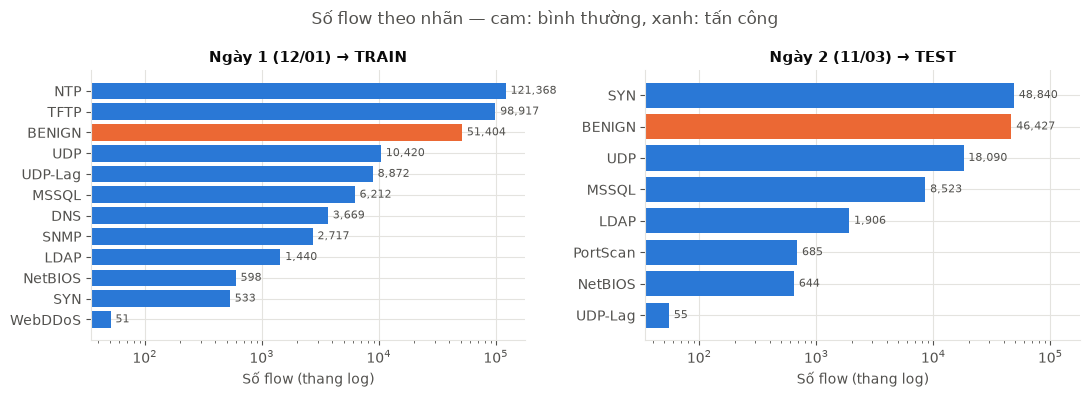

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, day in zip(axes, counts.columns):
    s = counts[day][counts[day] > 0].sort_values()
    ax.barh(s.index, s.values, color=[SERIES[1] if l == "BENIGN" else SERIES[0] for l in s.index])
    ax.set_xscale("log"); ax.set_title(day); ax.set_xlabel("Số flow (thang log)")
    for y, v in enumerate(s.values):
        ax.text(v * 1.1, y, f"{v:,}", va="center", fontsize=8, color=INK2)
fig.suptitle("Số flow theo nhãn — cam: bình thường, xanh: tấn công", color=INK2)
plt.tight_layout(); plt.show()

Trục ngang là **thang log**: mỗi vạch gấp 10 lần. NTP/TFTP (~100.000) nhiều gấp ~2.000 lần WebDDoS (51). Vì vậy:
- Khi tiền xử lý, mỗi loại tấn công bị **giới hạn tối đa 30.000 dòng** (giữ toàn bộ BENIGN) để một loại không lấn át các loại khác.
- Mô hình dùng **class weight** khi train, và đánh giá bằng **F1/Recall/FPR** chứ không dùng Accuracy (Accuracy cao giả khi một lớp chiếm đa số).

### Một dòng dữ liệu trông thế nào?
Một flow ngẫu nhiên có thể không đại diện, nên bảng dưới cho **giá trị trung vị** (giá trị ở giữa) của một số cột tiêu biểu, theo từng nhãn ở ngày train:

In [4]:
show_cols = ["protocol", "flow_duration", "total_fwd_packets", "total_backward_packets",
             "fwd_packets_length_total", "bwd_packets_length_total", "fwd_packet_length_min",
             "flow_bytes_s", "flow_packets_s", "syn_flag_count", "ack_flag_count", "init_fwd_win_bytes"]
day1 = raw[raw["day"].str.startswith("Ngày 1")]
day1[day1.label.isin(["BENIGN", "SYN", "NTP", "DNS"])].groupby("label")[show_cols].median().T

label,BENIGN,DNS,NTP,SYN
protocol,6.000000,17.0,1.700000e+01,6.000000e+00
flow_duration,20925.500000,2.0,1.097500e+03,6.015393e+06
total_fwd_packets,2.000000,2.0,4.400000e+01,4.000000e+00
total_backward_packets,2.000000,0.0,0.000000e+00,2.000000e+00
fwd_packets_length_total,70.000000,2814.0,1.878400e+04,0.000000e+00
bwd_packets_length_total,102.000000,0.0,0.000000e+00,0.000000e+00
fwd_packet_length_min,0.000000,1368.0,4.400000e+02,0.000000e+00
flow_bytes_s,4165.172908,480000000.0,1.643966e+07,0.000000e+00
flow_packets_s,191.644308,1000000.0,3.829837e+04,7.472443e-01
syn_flag_count,0.000000,0.0,0.000000e+00,0.000000e+00


**Nhận xét:**
- **NTP, DNS (phản xạ)**: UDP (`protocol` = 17), gói chiều đi **rất lớn** (`fwd_packet_length_min` 440–1.368 byte), **0 gói chiều về**, tốc độ gói cực cao (DNS: 1 triệu gói/giây), không có cửa sổ TCP (−1).
- **SYN**: TCP, **payload = 0 byte** (chỉ có header), cửa sổ TCP 5.840 (đặc trưng của công cụ tấn công), thời lượng dài nhưng rất ít gói/giây.
- **BENIGN**: TCP/UDP lẫn lộn, có trao đổi **hai chiều**.

⚠️ **Một bẫy cho người mới**: cột `syn_flag_count` bằng **0 ở 100% flow SYN**. Không phải SYN flood không có cờ SYN — đây là **hạn chế đã biết của CICFlowMeter** khi đếm cờ TCP (nhiều nghiên cứu đã chỉ ra lỗi của công cụ này, vd. Engelen và cộng sự, 2021). Vì vậy đừng giải thích kết quả bằng cột cờ SYN; mô hình nhận ra SYN qua các cột khác (payload 0, cửa sổ TCP, IAT).

Đơn vị: `flow_duration` và các cột IAT tính bằng **micro giây (µs)**; `protocol`: **6 = TCP, 17 = UDP, 0 = khác**.

## 4. Các nhóm đặc trưng của CICFlowMeter

Dataset có 77 cột đặc trưng. Chúng thuộc vài nhóm lớn:

| Nhóm | Ví dụ cột | Ý nghĩa |
|---|---|---|
| Thời lượng | `flow_duration` | Flow kéo dài bao lâu (µs) |
| Số gói | `total_fwd_packets`, `total_backward_packets` | Bao nhiêu gói mỗi chiều |
| Khối lượng | `fwd_packets_length_total`, `bwd_packets_length_total` | Tổng byte payload mỗi chiều |
| Kích thước gói | `fwd_packet_length_min/max/mean/std`, `packet_length_*` | Gói to hay nhỏ, có đều không |
| Tốc độ | `flow_bytes_s`, `flow_packets_s`, `bwd_packets_s` | Byte/giây, gói/giây |
| IAT (Inter-Arrival Time) | `flow_iat_*`, `fwd_iat_*`, `bwd_iat_*` | Khoảng thời gian giữa 2 gói liên tiếp |
| Cờ TCP | `syn_flag_count`, `ack_flag_count`, `urg_flag_count`… | Số gói có cờ đó |
| Header / cửa sổ TCP | `fwd_header_length`, `init_fwd_win_bytes` | Kích thước header, cửa sổ TCP ban đầu |
| Bulk / Subflow / Active-Idle | `subflow_*`, `active_*`, `idle_*` | Thống kê theo đợt truyền, thời gian hoạt động/nghỉ |

Từ 77 cột, `prepare/preprocess_csv.py` giữ lại **25 đặc trưng** bằng 2 bước (mục 4.2 tài liệu):
1. Bỏ cột hằng và **một trong hai cột có tương quan Pearson > 0,95** (thông tin trùng lặp) → bỏ 21 cột.
2. Xếp hạng phần còn lại bằng **Random Forest importance**, lấy 25 cột đứng đầu.

Bảng dưới giải thích từng đặc trưng được chọn, kèm trung vị ở flow bình thường vs flow tấn công (ngày train):

In [5]:
FEATURE_VI = {
    "fwd_packet_length_min": ("Kích thước gói", "Gói nhỏ nhất chiều đi (byte)"),
    "fwd_packet_length_max": ("Kích thước gói", "Gói lớn nhất chiều đi (byte)"),
    "packet_length_max": ("Kích thước gói", "Gói lớn nhất cả hai chiều (byte)"),
    "bwd_packet_length_max": ("Kích thước gói", "Gói lớn nhất chiều về (byte)"),
    "bwd_packet_length_mean": ("Kích thước gói", "Kích thước TB gói chiều về (byte)"),
    "total_backward_packets": ("Số gói", "Số gói chiều về — reflection/flood thường = 0"),
    "fwd_packets_length_total": ("Khối lượng", "Tổng byte chiều đi"),
    "bwd_packets_length_total": ("Khối lượng", "Tổng byte chiều về"),
    "bwd_header_length": ("Header", "Tổng byte header chiều về"),
    "bwd_iat_max": ("IAT", "Khoảng cách lớn nhất giữa 2 gói chiều về (µs)"),
    "bwd_iat_mean": ("IAT", "Khoảng cách TB giữa 2 gói chiều về (µs)"),
    "bwd_iat_min": ("IAT", "Khoảng cách nhỏ nhất giữa 2 gói chiều về (µs)"),
    "bwd_iat_total": ("IAT", "Tổng thời gian giữa các gói chiều về (µs)"),
    "flow_iat_max": ("IAT", "Khoảng cách lớn nhất giữa 2 gói bất kỳ (µs)"),
    "flow_iat_mean": ("IAT", "Khoảng cách TB giữa 2 gói (µs)"),
    "flow_iat_std": ("IAT", "Độ lệch chuẩn khoảng cách giữa các gói"),
    "fwd_iat_mean": ("IAT", "Khoảng cách TB giữa 2 gói chiều đi (µs)"),
    "bwd_packets_s": ("Tốc độ", "Số gói chiều về mỗi giây"),
    "flow_packets_s": ("Tốc độ", "Số gói mỗi giây (cả hai chiều)"),
    "protocol": ("Cơ bản", "Giao thức: 6 = TCP, 17 = UDP, 0 = khác"),
    "urg_flag_count": ("Cờ TCP", "Số gói có cờ URG"),
    "ack_flag_count": ("Cờ TCP", "Số gói có cờ ACK — kết nối thật có ACK, SYN flood thì không"),
    "init_fwd_win_bytes": ("Cửa sổ TCP", "Cửa sổ TCP ban đầu chiều đi (−1 nếu không phải TCP)"),
    "init_bwd_win_bytes": ("Cửa sổ TCP", "Cửa sổ TCP ban đầu chiều về"),
    "down_up_ratio": ("Tỉ lệ", "Tỉ lệ gói chiều về / chiều đi"),
}
feats = load_meta(DATA / "features.json")["features"]
tr = day1.copy()
is_att = tr["label"] != "BENIGN"
tbl = pd.DataFrame([{
    "Hạng": i + 1, "Đặc trưng": f,
    "Nhóm": FEATURE_VI.get(f, ("?", ""))[0], "Ý nghĩa": FEATURE_VI.get(f, ("?", "(chưa có mô tả)"))[1],
    "Trung vị BENIGN": tr.loc[~is_att, f].median(), "Trung vị tấn công": tr.loc[is_att, f].median(),
} for i, f in enumerate(feats)])
tbl.style.format({"Trung vị BENIGN": "{:,.1f}", "Trung vị tấn công": "{:,.1f}"}).hide(axis="index")

Hạng,Đặc trưng,Nhóm,Ý nghĩa,Trung vị BENIGN,Trung vị tấn công
1,fwd_packet_length_min,Kích thước gói,Gói nhỏ nhất chiều đi (byte),0.0,440.0
2,total_backward_packets,Số gói,Số gói chiều về — reflection/flood thường = 0,2.0,0.0
3,bwd_iat_max,IAT,Khoảng cách lớn nhất giữa 2 gói chiều về (µs),3.0,0.0
4,bwd_iat_mean,IAT,Khoảng cách TB giữa 2 gói chiều về (µs),2.0,0.0
5,bwd_iat_min,IAT,Khoảng cách nhỏ nhất giữa 2 gói chiều về (µs),2.0,0.0
6,fwd_packet_length_max,Kích thước gói,Gói lớn nhất chiều đi (byte),35.0,440.0
7,packet_length_max,Kích thước gói,Gói lớn nhất cả hai chiều (byte),57.0,440.0
8,bwd_packets_s,Tốc độ,Số gói chiều về mỗi giây,61.9,0.0
9,bwd_header_length,Header,Tổng byte header chiều về,40.0,0.0
10,protocol,Cơ bản,"Giao thức: 6 = TCP, 17 = UDP, 0 = khác",6.0,17.0


**Cách đọc**: Hạng 1 là đặc trưng Random Forest dựa vào nhiều nhất. `fwd_packet_length_min` đứng đầu vì tấn công phản xạ gửi gói **to và đều** (gói nhỏ nhất cũng lớn), còn traffic bình thường có nhiều gói nhỏ (ACK, handshake). Nhóm **IAT chiều về** đứng cao vì nhiều tấn công **không có chiều về** (nạn nhân không trả lời hoặc reflection một chiều).

## 5. Đặc trưng phân biệt tấn công như thế nào?

Biểu đồ hộp (boxplot) dưới đây so sánh phân phối 4 đặc trưng giữa các nhãn ở ngày train. Trục tung là `log1p` vì giá trị trải từ 0 đến hàng triệu. Hộp = 50% dữ liệu ở giữa, vạch trong hộp = trung vị.

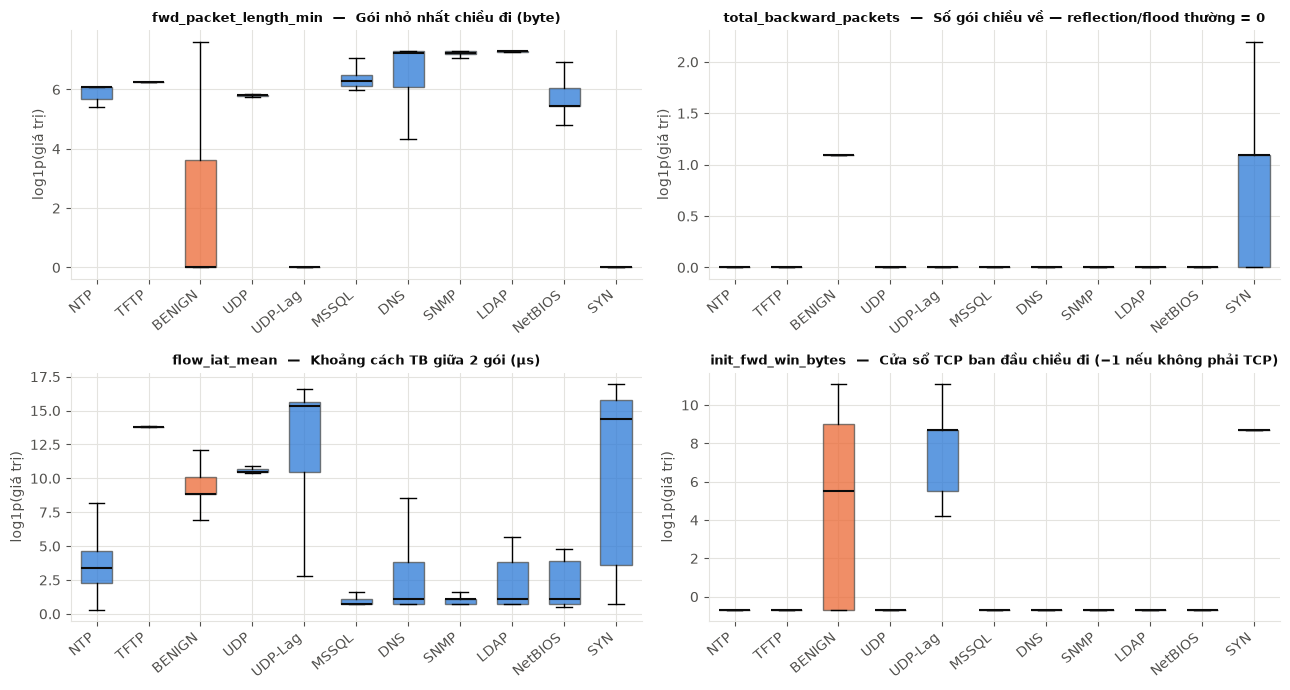

In [6]:
order = counts.index[counts["Ngày 1 (12/01) → TRAIN"] > 100].tolist()
show = ["fwd_packet_length_min", "total_backward_packets", "flow_iat_mean", "init_fwd_win_bytes"]
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, f in zip(axes.ravel(), show):
    data = [slog1p(tr.loc[tr.label == l, f].values) for l in order]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
    for b, l in zip(bp["boxes"], order):
        b.set(facecolor=SERIES[1] if l == "BENIGN" else SERIES[0], alpha=0.75, edgecolor=INK2)
    for m in bp["medians"]:
        m.set(color=INK, linewidth=1.5)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=40, ha="right")
    ax.set_title(f"{f}  —  {FEATURE_VI.get(f, ('', ''))[1]}", fontsize=9)
    ax.set_ylabel("log1p(giá trị)")
plt.tight_layout(); plt.show()

**Quan sát:**
- `fwd_packet_length_min`: các tấn công phản xạ (DNS, LDAP, NTP, SNMP…) cao hẳn; SYN ≈ 0 (gói SYN không có payload).
- `total_backward_packets`: mọi tấn công UDP có **0 gói chiều về** (nạn nhân không trả lời); BENIGN và SYN có ~2 gói → riêng đặc trưng này không tách được SYN khỏi BENIGN.
- `flow_iat_mean`: SYN và UDP-Lag có khoảng cách giữa các gói **rất dài** (gửi chậm, giữ kết nối), reflection thì cực ngắn.
- `init_fwd_win_bytes`: chỉ TCP mới có cửa sổ; flow UDP mang −1 → tách TCP (SYN, BENIGN web, phần lớn UDP-Lag) khỏi UDP. SYN có giá trị **cố định 5.840** — "dấu vân tay" của công cụ tấn công.
- Mỗi loại tấn công có "chữ ký" riêng → mô hình phải **thấy** loại đó khi train mới nhận ra tốt. Đây là lý do thiếu dữ liệu một loại (như SYN) gây hậu quả lớn.

Giao thức theo từng nhãn:

In [7]:
proto = pd.crosstab(tr["label"], tr["protocol"].map({6: "TCP", 17: "UDP", 0: "Khác"}), normalize="index")
(proto * 100).round(1).loc[order]

protocol,Khác,TCP,UDP
label,,,
NTP,0.0,0.3,99.7
TFTP,0.0,0.3,99.7
BENIGN,1.8,57.4,40.9
UDP,0.0,0.0,100.0
UDP-Lag,0.0,75.2,24.8
MSSQL,0.0,0.0,100.0
DNS,0.0,0.2,99.8
SNMP,0.0,0.1,99.9
LDAP,0.0,0.4,99.6


Các tấn công phản xạ là **UDP ≥ 99%**; SYN là **TCP 100%**; BENIGN lẫn cả hai (57% TCP, 41% UDP).

**Điểm lạ: UDP-Lag có tới 75% flow là TCP.** Lý do: CIC gán nhãn theo **khung giờ và IP của đợt tấn công**, nên mọi flow giữa máy tấn công và nạn nhân trong khung giờ đó đều mang nhãn tấn công, kể cả traffic phụ. Đây là **nhiễu nhãn** (label noise) của dataset — nên nhắc trong phần "Hạn chế" của báo cáo.

## 6. Chất lượng dữ liệu

Các vấn đề phổ biến của CICFlowMeter: giá trị **vô cùng (inf)** khi chia cho thời lượng 0, **NaN**, **dòng trùng lặp** và **cột hằng** (luôn bằng một giá trị).

In [8]:
num = raw.drop(columns=["file", "day", "label", "Label"]).apply(pd.to_numeric, errors="coerce")
q = pd.DataFrame({
    "Số dòng có inf": [int(np.isinf(num.values.astype(float)).any(axis=1).sum())],
    "Số dòng có NaN": [int(num.isna().any(axis=1).sum())],
    "Số dòng trùng lặp": [int(raw.drop(columns=["file"]).duplicated().sum())],
    "Số cột hằng": [int((num.nunique() <= 1).sum())],
})
display(q)
print("Cột hằng:", list(num.columns[num.nunique() <= 1]))

,Số dòng có inf,Số dòng có NaN,Số dòng trùng lặp,Số cột hằng
0,0,0,5049,12


Cột hằng: ['bwd_psh_flags', 'fwd_urg_flags', 'bwd_urg_flags', 'fin_flag_count', 'psh_flag_count', 'ece_flag_count', 'fwd_avg_bytes_bulk', 'fwd_avg_packets_bulk', 'fwd_avg_bulk_rate', 'bwd_avg_bytes_bulk', 'bwd_avg_packets_bulk', 'bwd_avg_bulk_rate']


Bản Kaggle đã sạch inf/NaN, nhưng vẫn còn **~5.000 dòng trùng** và **12 cột hằng** (các cột Bulk và một số cờ TCP luôn bằng 0 — lại là hệ quả của cách CICFlowMeter đếm cờ). Pipeline vẫn luôn: thay inf → NaN rồi xóa, xóa trùng, bỏ cột hằng — để chạy được cả với CSV gốc (vốn có nhiều inf). Ngoài ra **các cột định danh** (IP, Flow ID, Timestamp, port nguồn) **bị xóa** — nếu giữ lại, mô hình sẽ "học vẹt" IP của kẻ tấn công trong testbed thay vì học hành vi traffic.

## 7. Tương quan giữa 25 đặc trưng được chọn

Đã bỏ các cặp tương quan > 0,95, nhưng vẫn còn những nhóm liên quan (vd. các IAT chiều về). Màu đỏ = tương quan dương, xanh = âm, trắng = không liên quan.

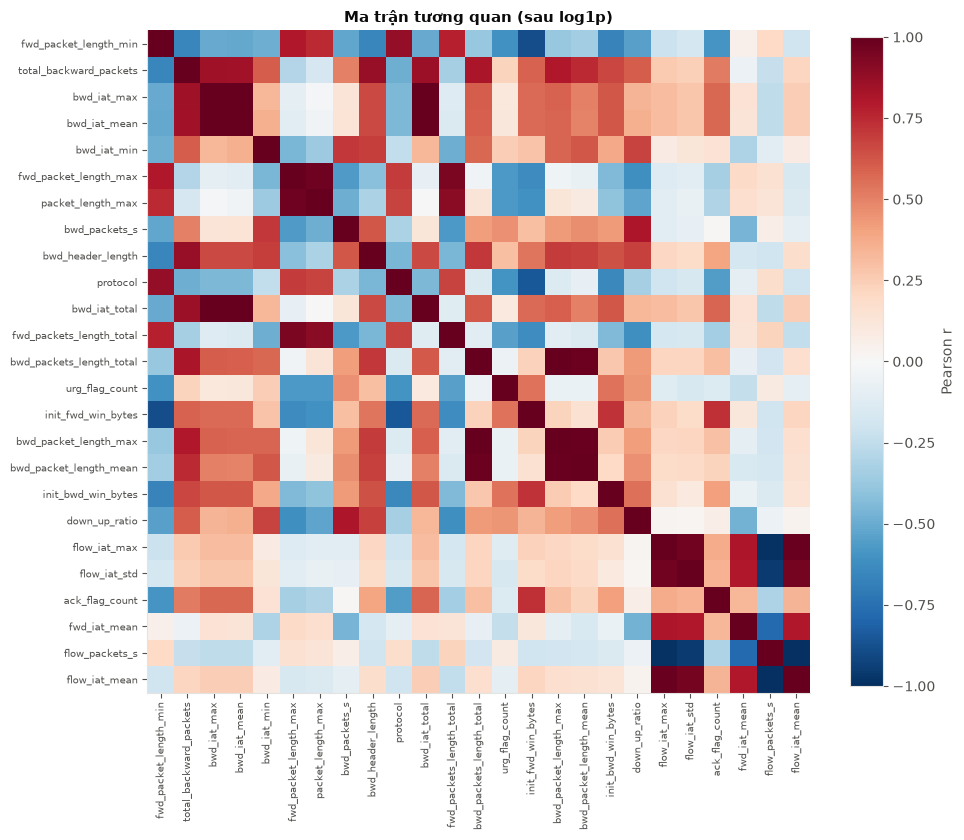

In [9]:
pool = pd.read_parquet(DATA / "train_pool.parquet")
corr = pool[feats].corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(feats)), feats, rotation=90, fontsize=7)
ax.set_yticks(range(len(feats)), feats, fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.04, label="Pearson r")
ax.set_title("Ma trận tương quan (sau log1p)")
plt.tight_layout(); plt.show()

## 8. ⭐ Hai ngày khác nhau ra sao? (chìa khóa để hiểu kết quả)

Mô hình học ở ngày 12/01 nhưng bị chấm điểm ở ngày 11/03. Nếu cùng một loại tấn công mà **phân phối đặc trưng khác nhau** giữa hai ngày (gọi là *distribution shift* / *concept drift*), mô hình sẽ nhận diện kém. So sánh số lượng trước:

In [10]:
common = [l for l in counts.index if (counts.loc[l] > 0).all()]
cmp = counts.loc[common].copy()
cmp["Tỉ lệ test/train"] = (cmp.iloc[:, 1] / cmp.iloc[:, 0]).round(1)
cmp

day,Ngày 1 (12/01) → TRAIN,Ngày 2 (11/03) → TEST,Tỉ lệ test/train
label,,,
BENIGN,51404,46427,0.9
UDP,10420,18090,1.7
UDP-Lag,8872,55,0.0
MSSQL,6212,8523,1.4
LDAP,1440,1906,1.3
NetBIOS,598,644,1.1
SYN,533,48840,91.6


**SYN: train chỉ 533 flow nhưng test có 48.840** (gấp ~92 lần); sau tiền xử lý SYN chiếm **gần 40% tập test**. UDP-Lag thì ngược lại: 8.872 ở train, chỉ 55 ở test. Mô hình gần như "mới thấy SYN vài lần" nhưng bị kiểm tra chủ yếu bằng SYN. So sánh phân phối đặc trưng của SYN giữa hai ngày:

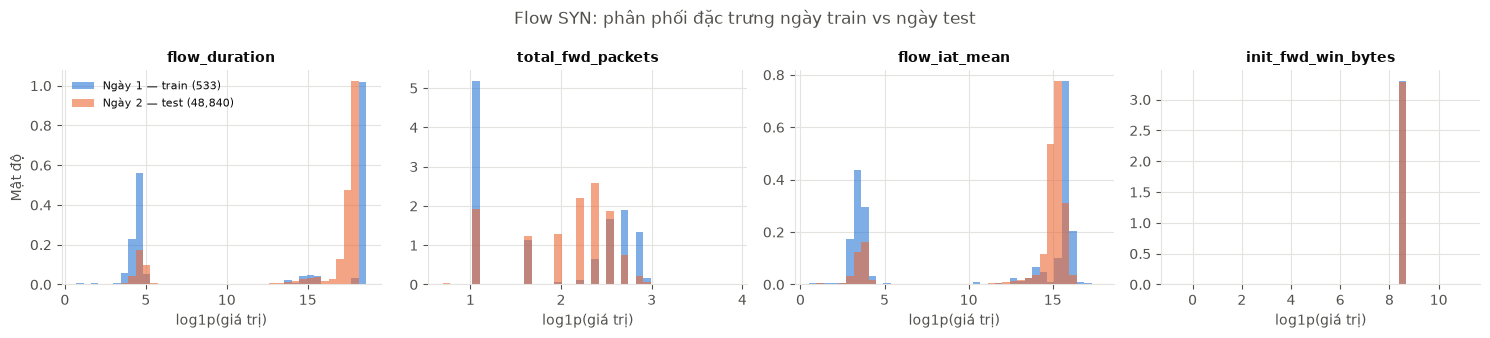

In [11]:
syn1 = raw[(raw.label == "SYN") & raw.day.str.startswith("Ngày 1")]
syn2 = raw[(raw.label == "SYN") & raw.day.str.startswith("Ngày 2")]
show = ["flow_duration", "total_fwd_packets", "flow_iat_mean", "init_fwd_win_bytes"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, f in zip(axes, show):
    a, b = slog1p(syn1[f].values), slog1p(syn2[f].values)
    bins = np.linspace(min(a.min(), b.min()), max(a.max(), b.max()) + 1e-9, 40)
    ax.hist(a, bins=bins, density=True, alpha=0.6, color=SERIES[0], label=f"Ngày 1 — train ({len(a):,})")
    ax.hist(b, bins=bins, density=True, alpha=0.6, color=SERIES[1], label=f"Ngày 2 — test ({len(b):,})")
    ax.set_title(f, fontsize=10); ax.set_xlabel("log1p(giá trị)")
axes[0].set_ylabel("Mật độ"); axes[0].legend(fontsize=8)
fig.suptitle("Flow SYN: phân phối đặc trưng ngày train vs ngày test", color=INK2)
plt.tight_layout(); plt.show()

Hai ngày có **cùng dạng** (hai cụm: flow rất ngắn và flow rất dài; cùng cửa sổ TCP 5.840) nhưng **tỉ lệ khác nhau**: ngày test có nhiều flow dài hơn, và nhiều flow 6–10 gói (`total_fwd_packets` ≈ 2,0–2,5 trên thang log) mà ngày train gần như không có. Vấn đề chính vì vậy là **số lượng**: chỉ 533 mẫu thì mô hình không phủ được hết các biến thể SYN xuất hiện ở ngày test. Đây là lý do:
- F1 trên dữ liệu thật thấp hơn hẳn dữ liệu giả;
- **FedAvg đạt đỉnh sớm (vòng 2–4) rồi tụt dần** — càng train, mô hình càng khớp với phân phối ngày 1 và "quên" vùng SYN của ngày 2;
- **FedProx giữ ổn định hơn** — số hạng phạt kéo mô hình về gần mô hình toàn cục, đóng vai trò regularization.

Notebook `02_phan_tich_ket_qua.ipynb` kiểm chứng điều này bằng số liệu.

## 9. Chia dữ liệu cho các client — mô phỏng Non-IID

Federated Learning giả lập 5 "chi nhánh" (client), mỗi chi nhánh chỉ thấy một phần dữ liệu. **IID** = mọi client có phân phối giống nhau; **Non-IID** = mỗi client thấy phân phối khác nhau (thực tế hơn). Bốn kịch bản (`prepare/split_clients.py`):

| Kịch bản | Cách chia | Ý nghĩa |
|---|---|---|
| S1 | Xáo trộn, chia đều | Trường hợp lý tưởng (IID) |
| S2a / S2b | Dirichlet α = 0,5 / 0,1 theo nhãn | α càng nhỏ, mỗi client càng lệch về vài loại |
| S3 | Mỗi client một nhóm tấn công, ai cũng có BENIGN | Giống thực tế: mỗi chi nhánh gặp kiểu DDoS khác nhau |
| S4 | Client lớn nhất 50% dữ liệu, nhỏ nhất 5% | Kiểm tra trọng số n_k/n của FedAvg |

Biểu đồ: mỗi thanh là một client, chia màu theo nhóm nhãn (các loại ít mẫu gộp vào "Khác" để dễ đọc).

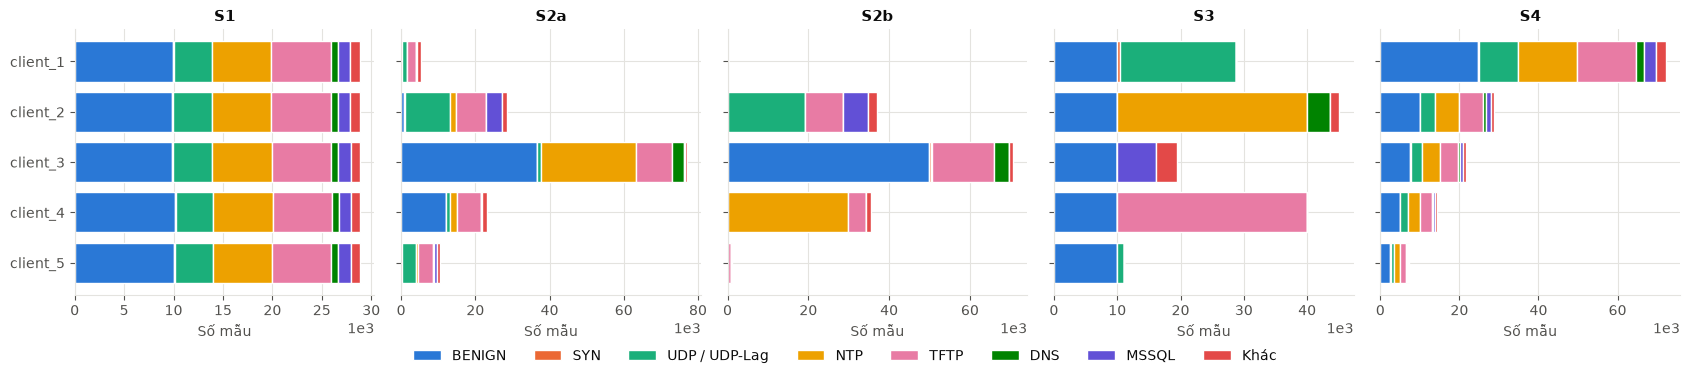

In [12]:
GROUP = {"BENIGN": "BENIGN", "SYN": "SYN", "UDP": "UDP / UDP-Lag", "UDP-Lag": "UDP / UDP-Lag",
         "NTP": "NTP", "TFTP": "TFTP", "DNS": "DNS", "MSSQL": "MSSQL"}
groups = ["BENIGN", "SYN", "UDP / UDP-Lag", "NTP", "TFTP", "DNS", "MSSQL", "Khác"]
colors = dict(zip(groups, SERIES))
scen = ["S1", "S2a", "S2b", "S3", "S4"]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), sharey=True)
for ax, sc in zip(axes, scen):
    s = pd.read_csv(DATA / sc / "summary.csv", index_col=0).drop(index="TOTAL")
    g = s.groupby(lambda l: GROUP.get(l, "Khác")).sum().reindex(groups).fillna(0)
    left = np.zeros(g.shape[1])
    for grp in groups:
        ax.barh(g.columns, g.loc[grp], left=left, color=colors[grp], label=grp, edgecolor="white", linewidth=1)
        left += g.loc[grp].values
    ax.set_title(sc); ax.set_xlabel("Số mẫu"); ax.invert_yaxis()
    ax.ticklabel_format(axis="x", style="sci", scilimits=(3, 3))
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=8, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); plt.show()

**Quan sát:**
- **S1**: 5 thanh giống hệt nhau.
- **S2b (α = 0,1)**: client 1 chỉ có **~200 mẫu**, client 3 có ~70.000 → lệch cực đoan cả về số lượng lẫn loại.
- **S3**: SYN **chỉ nằm ở client 1** (và chỉ 533 mẫu); NTP chỉ ở client 2; TFTP chỉ ở client 4. Mỗi chi nhánh là "chuyên gia" của vài loại — FL phải truyền kiến thức giữa các chi nhánh.
- **S4**: cùng phân phối nhãn, chỉ khác kích thước.

## 10. Chuẩn hóa liên kết có đúng không?

Mạng nơ-ron cần đặc trưng được chuẩn hóa (trừ mean, chia std). Nếu server gom dữ liệu thô của mọi client để tính mean/std thì **vi phạm tinh thần FL**. Cách làm của đồ án (mục 4.5): mỗi client chỉ gửi **n, Σx, Σx²** — không lộ từng flow — server tự suy ra:

$$\mu = \frac{\sum_k \sum x}{\sum_k n_k}, \qquad \sigma^2 = \frac{\sum_k \sum x^2}{\sum_k n_k} - \mu^2$$

Kiểm chứng: kết quả phải **trùng** với việc tính trực tiếp trên dữ liệu gộp.

In [13]:
from prepare.federated_scaler import client_stats, aggregate
files = sorted((DATA / "S3").glob("client_*.parquet"))
stats = [client_stats(pd.read_parquet(f), feats) for f in files]
fed = aggregate(stats)
pooled = pd.concat([pd.read_parquet(f) for f in files])[feats]
print("Mỗi client gửi lên:", {k: (v.shape if hasattr(v, "shape") else v) for k, v in stats[0].items()})
print("Sai lệch lớn nhất của mean:", np.abs(np.array(fed["mean"]) - pooled.mean().values).max())
print("Sai lệch lớn nhất của std :", np.abs(np.array(fed["std"]) - pooled.std(ddof=0).values).max())

Mỗi client gửi lên: {'n': 28753, 'sum': (25,), 'sumsq': (25,)}
Sai lệch lớn nhất của mean: 1.0472285172369311e-06
Sai lệch lớn nhất của std : 3.0840262876807856e-07


Sai lệch chỉ cỡ 1e-6 — đúng bằng sai số làm tròn vì dữ liệu được lưu dạng `float32` → chuẩn hóa liên kết **cho kết quả như nhau** so với chuẩn hóa tập trung, trong khi server chỉ nhận 3 thống kê × 25 đặc trưng mỗi client.

## Tóm tắt

| Điều cần nhớ | Hệ quả cho đồ án |
|---|---|
| Mỗi dòng là một **flow** với ~77 đặc trưng thống kê từ CICFlowMeter | Mô hình phân loại từng flow; đặc trưng khác với Suricata (Nhánh B) |
| Train ngày 12/01, test ngày 11/03; PortScan chỉ có ở ngày test | Đánh giá trung thực, đo được khả năng tổng quát hóa |
| Bản Kaggle đảo tên file `-training`/`-testing` | Phải dùng `--train-glob *-testing` |
| Mất cân bằng mạnh giữa các loại | Giới hạn 30.000/loại, class weight, dùng F1/Recall/FPR |
| **SYN: 533 mẫu train vs ~48.000 mẫu test, phân phối khác nhau** | Nguyên nhân chính khiến F1 dao động và FedAvg suy giảm theo vòng |
| S3 đặt toàn bộ SYN vào một client | FL dễ "pha loãng" kiến thức hiếm của một chi nhánh |
| Chuẩn hóa liên kết = chuẩn hóa tập trung | Giữ đúng tinh thần FL mà không mất độ chính xác |

👉 Tiếp theo: **`02_phan_tich_ket_qua.ipynb`**.